# Day 2 · Notebook 1 — Where is the camera? PnP and the P3P solver

**Localisation against a 3D map** comes down to one problem:

> Given $n$ known 3D map points $\mathbf{X}_j$, where they appear in the image $\mathbf{x}_j$, and the intrinsics $K$, find the camera pose $(R, \mathbf{t})$.

This is the **Perspective-n-Point (PnP)** problem. We already used it inside VO (Day 1, Notebook 2) and COLMAP's image registration.

* Unknowns: 6 DOF (3 rotation + 3 translation)
* Each 2D–3D correspondence gives 2 equations ($u$ and $v$)
* So the minimal case is **3 points: P3P** (Grunert 1841!). It has up to **4** solutions.

Plan: (1) build a P3P solver from scratch, (2) see the 4 solutions, (3) PnP with many noisy points, (4) RANSAC with outliers.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from numpy.polynomial import polynomial as Pl

rng = np.random.default_rng(0)
K = np.array([[800, 0, 320], [0, 800, 240], [0, 0, 1.0]])
W_IMG, H_IMG = 640, 480

def project(X, R, t, K=K):
    Xc = X @ R.T + t
    uv = Xc @ K.T
    return uv[:, :2] / uv[:, 2:3], Xc[:, 2]

def bearings(uv, K=K):
    """Unit viewing rays f = K^-1 [u v 1]^T / ||.||"""
    f = np.c_[uv, np.ones(len(uv))] @ np.linalg.inv(K).T
    return f / np.linalg.norm(f, axis=1, keepdims=True)

def random_scene(n, seed=None):
    r = np.random.default_rng(seed)
    X = r.uniform([-3, -2, 5], [3, 2, 10], (n, 3))          # map points in front of the camera
    R, _ = cv2.Rodrigues(r.normal(0, 0.15, 3))
    t = r.normal(0, 0.3, 3)
    return X, R, t

def pose_error(R, t, R_gt, t_gt):
    dR = np.degrees(np.arccos(np.clip((np.trace(R.T @ R_gt) - 1) / 2, -1, 1)))
    return dR, np.linalg.norm(t - t_gt)

## 1 · P3P geometry: three rays and a triangle

Camera centre $\mathbf{C}$, unit rays $\mathbf{f}_1, \mathbf{f}_2, \mathbf{f}_3$ (from the pixels and $K$). The unknown depths $s_i$ place the points at $s_i \mathbf{f}_i$ in the camera frame.

The **angles between the rays** are known from the image, and the **distances between the 3D points** are known from the map:

$$ \cos\alpha = \mathbf{f}_2^\top\mathbf{f}_3,\quad \cos\beta = \mathbf{f}_1^\top\mathbf{f}_3,\quad \cos\gamma = \mathbf{f}_1^\top\mathbf{f}_2 \qquad a = \|\mathbf{X}_2 - \mathbf{X}_3\|,\ b = \|\mathbf{X}_1 - \mathbf{X}_3\|,\ c = \|\mathbf{X}_1 - \mathbf{X}_2\| $$

The **law of cosines** on the three triangles $(\mathbf{C}, \mathbf{X}_i, \mathbf{X}_j)$:

$$
\begin{aligned}
a^2 &= s_2^2 + s_3^2 - 2 s_2 s_3 \cos\alpha \\
b^2 &= s_1^2 + s_3^2 - 2 s_1 s_3 \cos\beta \\
c^2 &= s_1^2 + s_2^2 - 2 s_1 s_2 \cos\gamma
\end{aligned}
$$

Substitute $s_2 = u\,s_1$, $s_3 = v\,s_1$ and divide out $s_1^2$. You get **two conics** in $(u, v)$. Two conics meet in at most **4 points**, so we get a **quartic** in $v$ and up to 4 poses.

Finally, with the depths known we have the 3 points in **both** frames ($s_i\mathbf{f}_i$ and $\mathbf{X}_i$). The rigid transform between them comes from SVD (**Kabsch / Umeyama**).

In [2]:
def kabsch(A, B):
    """R, t minimising ||A - (R B + t)||  (A, B: Nx3 corresponding points)."""
    ma, mb = A.mean(0), B.mean(0)
    U, _, Vt = np.linalg.svd((A - ma).T @ (B - mb))
    D = np.diag([1, 1, np.sign(np.linalg.det(U @ Vt))])     # avoid reflections
    R = U @ D @ Vt
    return R, ma - R @ mb

def p3p(f, X):
    """f: 3 unit bearings (3x3), X: 3 world points (3x3) -> list of (R, t) with x_cam = R X + t."""
    a = np.linalg.norm(X[1] - X[2]); b = np.linalg.norm(X[0] - X[2]); c = np.linalg.norm(X[0] - X[1])
    ca, cb, cg = f[1] @ f[2], f[0] @ f[2], f[0] @ f[1]
    # conic (i)  [from b^2 and c^2 eqs]: b^2 u^2 - 2 b^2 cg u + (b^2 - c^2 (1 + v^2 - 2 v cb)) = 0
    # conic (ii) [from b^2 and a^2 eqs]: b^2 u^2 - 2 b^2 ca v u + (b^2 v^2 - a^2 (1 + v^2 - 2 v cb)) = 0
    # (coefficient arrays are polynomials in v, lowest power first)
    k1 = np.array([b*b - c*c, 2*c*c*cb, -c*c]);  l1 = np.array([-2*b*b*cg])
    k2 = np.array([-a*a, 2*a*a*cb, b*b - a*a]);  l2 = np.array([0.0, -2*b*b*ca])
    # (i) - (ii) is linear in u:  u = num(v) / den(v)
    num, den = -Pl.polysub(k1, k2), Pl.polysub(l1, l2)
    # put u back into (i), multiply by den^2  ->  quartic in v
    quartic = Pl.polyadd(Pl.polyadd(b*b * Pl.polymul(num, num), Pl.polymul(l1, Pl.polymul(num, den))),
                         Pl.polymul(k1, Pl.polymul(den, den)))
    solutions = []
    for v in Pl.polyroots(quartic):
        if abs(v.imag) > 1e-8 or v.real <= 0:
            continue
        v = v.real
        u = Pl.polyval(v, num) / Pl.polyval(v, den)
        if u <= 0:
            continue
        s1 = c / np.sqrt(1 + u*u - 2*u*cg)
        depths = np.array([s1, u * s1, v * s1])
        solutions.append(kabsch(depths[:, None] * f, X))
    return solutions

# --- test on a random scene --------------------------------------------------
X, R_gt, t_gt = random_scene(4, seed=3)
uv, _ = project(X, R_gt, t_gt)
sols = p3p(bearings(uv[:3]), X[:3])
print(f"P3P gave {len(sols)} solution(s):")
for R, t in sols:
    dR, dt = pose_error(R, t, R_gt, t_gt)
    err4 = np.linalg.norm(project(X[3:], R, t)[0] - uv[3:])
    print(f"   rot err {dR:8.4f} deg   trans err {dt:.2e}   reprojection of 4th point {err4:8.2f} px")

n_cv, rvecs, tvecs = cv2.solveP3P(X[:3].reshape(-1, 1, 3), uv[:3].reshape(-1, 1, 2), K, None, flags=cv2.SOLVEPNP_P3P)
print("OpenCV cv2.solveP3P also finds", n_cv, "solution(s)")

P3P gave 2 solution(s):
   rot err   0.0000 deg   trans err 2.54e-11   reprojection of 4th point     0.00 px
   rot err 141.6038 deg   trans err 1.69e+01   reprojection of 4th point   172.37 px
OpenCV cv2.solveP3P also finds 2 solution(s)


## 2 · Seeing the ambiguity

All candidate poses project the 3 points **exactly** onto the same pixels. A **4th point** (or RANSAC voting with all points) picks the right one.

How often does each number of solutions occur?

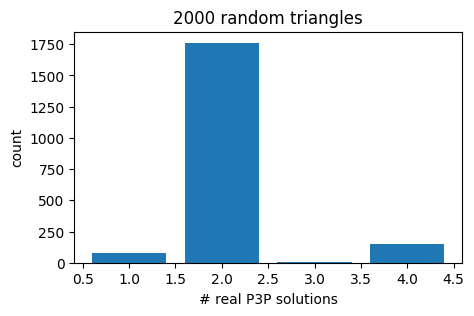

scene 7 has 4 solutions


In [3]:
counts = []
for s in range(2000):
    Xs, Rs, ts = random_scene(3, seed=1000 + s)
    counts.append(len(p3p(bearings(project(Xs, Rs, ts)[0]), Xs)))
vals, freq = np.unique(counts, return_counts=True)
plt.figure(figsize=(5, 3)); plt.bar(vals, freq); plt.xlabel("# real P3P solutions"); plt.ylabel("count")
plt.title("2000 random triangles"); plt.show()

# find a case with 4 solutions and draw them
for s in range(5000):
    Xs, Rs, ts = random_scene(4, seed=s)
    uv_s = project(Xs, Rs, ts)[0]
    ss = p3p(bearings(uv_s[:3]), Xs[:3])
    if len(ss) == 4:
        break
print("scene", s, "has", len(ss), "solutions")

def cam_trace(R, t, color, name, s=0.8):
    C = -R.T @ t
    corners = np.array([[-1, -0.75, 1.6], [1, -0.75, 1.6], [1, 0.75, 1.6], [-1, 0.75, 1.6]]) * s
    w = corners @ R + C          # = (R^T corners^T)^T + C
    p = np.array([C, w[0], C, w[1], C, w[2], C, w[3], w[0], w[1], w[2], w[3], w[0]])
    return go.Scatter3d(x=p[:, 0], y=p[:, 1], z=p[:, 2], mode="lines", line=dict(color=color, width=5), name=name)

traces = [go.Scatter3d(x=Xs[:3, 0], y=Xs[:3, 1], z=Xs[:3, 2], mode="markers+text", text=["X1", "X2", "X3"],
                       marker=dict(size=6, color="black"), name="3 map points"),
          go.Scatter3d(x=Xs[3:, 0], y=Xs[3:, 1], z=Xs[3:, 2], mode="markers", marker=dict(size=6, color="orange"),
                       name="4th point (check)")]
for k, ((R, t), col) in enumerate(zip(ss, ["green", "red", "blue", "purple"])):
    e4 = np.linalg.norm(project(Xs[3:], R, t)[0] - uv_s[3:])
    traces.append(cam_trace(R, t, col, f"solution {k}: 4th-point error {e4:.1f} px"))
    C = -R.T @ t
    for j in range(3):   # rays from each candidate centre to the 3 points
        traces.append(go.Scatter3d(x=[C[0], Xs[j, 0]], y=[C[1], Xs[j, 1]], z=[C[2], Xs[j, 2]], mode="lines",
                                   line=dict(color=col, width=1, dash="dot"), showlegend=False))
fig = go.Figure(traces)
fig.update_layout(scene=dict(aspectmode="data", camera=dict(up=dict(x=0, y=-1, z=0))), height=650,
                  title="Four camera poses that all see X1, X2, X3 at the same pixels")
fig.show()

## 3 · PnP with many (noisy) points

With $n \gg 3$ points we minimise the **reprojection error** over all of them:

$$ (R^*, \mathbf{t}^*) = \arg\min_{R, \mathbf{t}} \sum_{j=1}^{n} \big\| \mathbf{x}_j - \pi\!\left(K(R\mathbf{X}_j + \mathbf{t})\right) \big\|^2 $$

Typical recipe: a closed-form start (**EPnP**, Lepetit et al. 2009, $O(n)$; or SQPnP), then Levenberg–Marquardt refinement. More points and less pixel noise give a better pose.

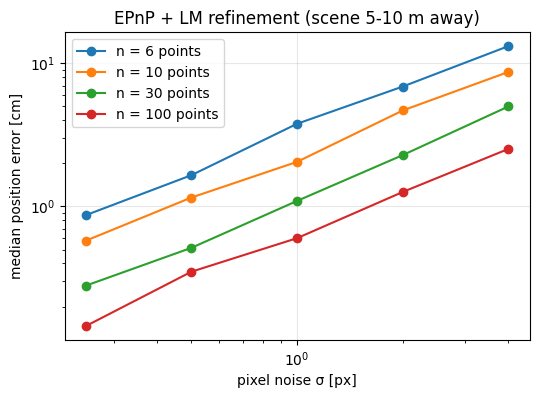

In [4]:
noise_levels = [0.25, 0.5, 1, 2, 4]
ns = [6, 10, 30, 100]
res = np.zeros((len(ns), len(noise_levels)))
for a, n in enumerate(ns):
    for b, sig in enumerate(noise_levels):
        errs = []
        for s in range(100):
            Xs, Rs, ts = random_scene(n, seed=10_000 + s)
            uv_n = project(Xs, Rs, ts)[0] + rng.normal(0, sig, (n, 2))
            ok, rvec, tvec = cv2.solvePnP(Xs, uv_n, K, None, flags=cv2.SOLVEPNP_EPNP)
            ok, rvec, tvec = cv2.solvePnP(Xs, uv_n, K, None, rvec, tvec, True, flags=cv2.SOLVEPNP_ITERATIVE)
            errs.append(pose_error(cv2.Rodrigues(rvec)[0], tvec.ravel(), Rs, ts)[1])
        res[a, b] = np.median(errs)

plt.figure(figsize=(6, 4))
for a, n in enumerate(ns):
    plt.plot(noise_levels, 100 * res[a], "o-", label=f"n = {n} points")
plt.xlabel("pixel noise σ [px]"); plt.ylabel("median position error [cm]"); plt.xscale("log"); plt.yscale("log")
plt.legend(); plt.title("EPnP + LM refinement (scene 5-10 m away)"); plt.grid(alpha=0.3); plt.show()

## 4 · Outliers: RANSAC around a minimal solver

Real 2D–3D matches contain **wrong** matches. A least-squares fit is dragged away by them. RANSAC:

1. sample **3** correspondences, run **P3P** (up to 4 hypotheses)
2. score each hypothesis: inliers = points with reprojection error $< \tau$ (e.g. 4 px)
3. keep the best, then **refine** with all its inliers (EPnP + LM)

With minimal sample size $s = 3$ instead of 6 (linear DLT), far fewer iterations are needed (Day 1 table).

Our own 20-line version first, then OpenCV's `solvePnPRansac`.

true outliers: 105/200;  our RANSAC found 94 inliers (94 correct, 0 wrong)
ours (RANSAC + refine): rot 0.036 deg, pos 0.005 m
no RANSAC (all points): rot 154.445 deg, pos 20.643 m
OpenCV solvePnPRansac: 91 inliers, rot 0.081 deg, pos 0.011 m


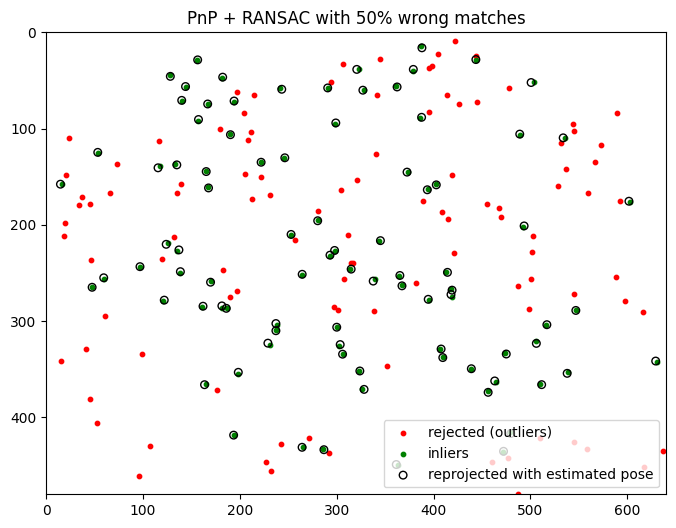

In [5]:
n, outlier_ratio = 200, 0.5
Xs, Rs, ts = random_scene(n, seed=7)
uv_obs = project(Xs, Rs, ts)[0] + rng.normal(0, 1.0, (n, 2))
is_out = rng.random(n) < outlier_ratio
uv_obs[is_out] = rng.uniform([0, 0], [W_IMG, H_IMG], (is_out.sum(), 2))    # random wrong matches
f_obs = bearings(uv_obs)

def ransac_p3p(X, uv, f, tau=4.0, iters=200):
    best_inl, best = np.zeros(len(X), bool), None
    for _ in range(iters):
        idx = rng.choice(len(X), 3, replace=False)
        for R, t in p3p(f[idx], X[idx]):
            proj, z = project(X, R, t)
            inl = (np.linalg.norm(proj - uv, axis=1) < tau) & (z > 0)
            if inl.sum() > best_inl.sum():
                best_inl, best = inl, (R, t)
    return best, best_inl

(R0, t0), inl = ransac_p3p(Xs, uv_obs, f_obs)
ok, rvec, tvec = cv2.solvePnP(Xs[inl], uv_obs[inl], K, None, flags=cv2.SOLVEPNP_EPNP)
ok, rvec, tvec = cv2.solvePnP(Xs[inl], uv_obs[inl], K, None, rvec, tvec, True, flags=cv2.SOLVEPNP_ITERATIVE)
print(f"true outliers: {is_out.sum()}/{n};  our RANSAC found {inl.sum()} inliers "
      f"({(inl & ~is_out).sum()} correct, {(inl & is_out).sum()} wrong)")
print("ours (RANSAC + refine): rot %.3f deg, pos %.3f m" % pose_error(cv2.Rodrigues(rvec)[0], tvec.ravel(), Rs, ts))

ok, rvec_ls, tvec_ls = cv2.solvePnP(Xs, uv_obs, K, None, flags=cv2.SOLVEPNP_EPNP)
print("no RANSAC (all points): rot %.3f deg, pos %.3f m" % pose_error(cv2.Rodrigues(rvec_ls)[0], tvec_ls.ravel(), Rs, ts))

ok, rvec_cv, tvec_cv, inl_cv = cv2.solvePnPRansac(Xs, uv_obs, K, None, reprojectionError=4.0,
                                                  iterationsCount=1000, flags=cv2.SOLVEPNP_AP3P)
print(f"OpenCV solvePnPRansac: {len(inl_cv)} inliers, rot %.3f deg, pos %.3f m"
      % pose_error(cv2.Rodrigues(rvec_cv)[0], tvec_cv.ravel(), Rs, ts))

proj_best = project(Xs, cv2.Rodrigues(rvec)[0], tvec.ravel())[0]
plt.figure(figsize=(8, 6))
plt.scatter(*uv_obs[~inl].T, s=10, c="red", label="rejected (outliers)")
plt.scatter(*uv_obs[inl].T, s=10, c="green", label="inliers")
plt.scatter(*proj_best[inl].T, s=30, facecolors="none", edgecolors="k", label="reprojected with estimated pose")
plt.xlim(0, W_IMG); plt.ylim(H_IMG, 0); plt.legend(); plt.title("PnP + RANSAC with 50% wrong matches"); plt.show()

## Takeaways

* PnP = pose from 2D–3D matches. **3 points is the minimum (P3P), with up to 4 solutions.**
* In practice: **RANSAC + minimal solver** to get rid of outliers, then **least-squares refinement** on the inliers.
* This exact block is inside COLMAP's image registration, ORB-SLAM's tracking/relocalisation, and **hloc** (next notebook), which is about getting *good* 2D–3D matches at scale.

**Read more:** Haralick et al., *Review and analysis of solutions of the three point perspective pose estimation problem*, IJCV 1994 · Kneip et al., *A novel parametrization of the P3P problem*, CVPR 2011 · Lepetit et al., *EPnP*, IJCV 2009.